In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os


def read_frames(frames_path):
        # Read the frames from the specified path
        frames = []
        count = 0
        for filename in sorted(os.listdir(frames_path)):
            if filename.endswith(".jpg") or filename.endswith(".png"):
                frame_path = os.path.join(frames_path, filename)
                frame = cv2.imread(frame_path)
                # frame = cv2.resize(frame, (640, 640))  
                frames.append(frame)
                count += 1
                if count == 100:
                    break
                
        return frames
    
    
    


In [2]:
def extract_crops(bbox, frame , cont_batch , count):
    image = frame[int(bbox[1]) : int(bbox[3]), int(bbox[0]) : int(bbox[2])]
    cv2.imwrite(f'crops/crop_{cont_batch}_{count}.png', image)
    

In [3]:
import cv2
import os
import numpy as np
import pickle

# Load saved models
with open('./models/svm_model.pkl', 'rb') as f:
    svm = pickle.load(f)
with open('./models/vocabulary.pkl', 'rb') as f:
    vocabulary = pickle.load(f)
with open('./models/kmeans_model.pkl', 'rb') as f:
    kmeans = pickle.load(f)

num_clusters = vocabulary.shape[0]

# Initialize SIFT
sift = cv2.SIFT_create()

# Function to extract SIFT descriptors
def extract_sift_descriptors(img):
    keypoints, descriptors = sift.detectAndCompute(img, None)
    return descriptors

# Function to convert descriptors to BoVW histogram
def compute_bovw_feature(descriptors, kmeans, num_clusters):
    words = kmeans.predict(descriptors)
    histogram = np.zeros(num_clusters)
    for word in words:
        histogram[word] += 1
    histogram = histogram / np.sum(histogram)
    return histogram

# Path to test images
# test_images_path = "test_images"  # Update this with your actual path

# # Iterate over test images
# print("Predictions on new images:\n")
# for filename in os.listdir(test_images_path):
#     if filename.lower().endswith(('.jpg', '.png')):
#         image_path = os.path.join(test_images_path, filename)
        

In [19]:
def mask_on_white(img):
        height, width = img.shape[:2]

        # Crop 20% of the height from the top
        crop_height = int(height * 0.2)
        # crop_width = int(width * 0.1)
        cropped_img = img.copy()
        cropped_img[0:crop_height] = 0 # Crop from top and left


    # Your target BGR color
        bgr_color = np.uint8([[[181, 187, 173]]])  # BGR format
        hsv_color = cv2.cvtColor(bgr_color, cv2.COLOR_BGR2HSV)[0][0]
        # print("HSV color:", hsv_color)  # Just to check

        # Define a tolerance range
        h, s, v = hsv_color
        lower_bound = np.array([0,0, 200])  # Lower bound for hue, saturation, and value
        upper_bound = np.array([179, 50, 255])  # Upper bound for hue, saturation, and value

        # Convert input image to HSV
        hsv = cv2.cvtColor(cropped_img, cv2.COLOR_BGR2HSV)

        # Create the mask
        mask = cv2.inRange(hsv, lower_bound, upper_bound)

        kernel = np.ones((2, 2), np.uint8)  # Adjust size (e.g., 3x3 or 7x7) based on stripe width
        closed_image = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=2)

        # plt.imshow(mask, cmap='gray')
        return closed_image,cropped_img






In [5]:
def svm_features(cropped_img):
    descriptors = extract_sift_descriptors(cropped_img)
    if descriptors is not None:
        bovw_feature = compute_bovw_feature(descriptors, kmeans, num_clusters)
        bovw_feature = bovw_feature.reshape(1, -1)
        return bovw_feature
    return None
        # print(f"Image: {filename} => Predicted Class: {prediction}")


In [6]:
def adjust_svm_input(frame , bbox):

    svm_input = frame[int(bbox[1]) : int(bbox[3]), int(bbox[0]) : int(bbox[2])]

    # Desired size
    target_size = (128, 128)

    # Resize the cropped image
    resized_input = cv2.resize(svm_input, target_size, interpolation=cv2.INTER_CUBIC)

    
    return resized_input

In [20]:
def find_circles(mask,frame,cont_batch):
    test_frame = frame.copy()
    found = False
    count = 0
    y_min = 0  # Top of the image (farthest from camera)
    y_max = frame.shape[0]  # Bottom of the image (closest to camera)

    area_min_at_y_min = 20  # Smallest area when the ball is farthest
    area_max_at_y_min = 120
    area_min_at_y_max = 70  # Largest area when the ball is closest
    area_max_at_y_max = 600
    
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    for cnt in contours:
        coor_x, coor_y, w, h = cv2.boundingRect(cnt)
        area = cv2.contourArea(cnt)

        # Linearly interpolate the area bounds based on y
        # Fraction of y between y_min and y_max
        y_fraction = (coor_y - y_min) / (y_max - y_min)
        
        # Interpolate area bounds
        area_min = area_min_at_y_min + y_fraction * (area_min_at_y_max - area_min_at_y_min)
        area_max = area_max_at_y_min + y_fraction * (area_max_at_y_max - area_max_at_y_min)

        # # Adjust the condition dynamically
        # if 400 < coor_y < 600 and 600 < coor_x < 900 and area > 40:   
        cv2.rectangle(test_frame, (coor_x, coor_y), (coor_x + w, coor_y + h), (255, 255, 0), 2)
        print("\nArea:", area , "Area_min:", area_min, "Area_max:", area_max )
        print("coor_x:", coor_x , "coor_y:", coor_y )
        # if area_min < area < area_max:
        if area == 0:
            continue
        (x, y), radius = cv2.minEnclosingCircle(cnt)
        circularity = 4 * np.pi * area / (cv2.arcLength(cnt, True) ** 2)
        if circularity > 0.45:  # adjust based on your needs
            # extract_crops([coor_x, coor_y, coor_x + w, coor_y + h], frame, cont_batch , count)
            bbox = [coor_x, coor_y, coor_x + w, coor_y + h]
            svm_input = adjust_svm_input(frame, bbox)
            features = svm_features(svm_input)
            prediction = svm.predict(features)[0] if features is not None else 0
            if prediction == 1:
                found = True
                cv2.rectangle(test_frame, (coor_x, coor_y), (coor_x + w, coor_y + h), (255, 0, 0), 2)
            else:
                cv2.rectangle(test_frame, (coor_x, coor_y), (coor_x + w, coor_y + h), (0, 0, 255), 2)
            if features is not None and not np.isnan(features).any():
                probs = svm.predict_proba(np.array(features).reshape(1, -1))[0]
                confidence = max(probs)
            else:

                confidence = 0.0

            font = cv2.FONT_HERSHEY_SIMPLEX
            font_scale = 1
            thickness = 2
            label = f"A:{area:.2f},C:{circularity:.2f},P:{prediction},CONF:{confidence:.2f}"
            text_size, _ = cv2.getTextSize(label, font, font_scale, thickness)
            text_x = int(x) + int(radius) + 5  # Position text to the right of the circle
            text_y = int(y) + int(text_size[1] // 2)  # Center text vertically with circle
            cv2.putText(test_frame, label, (text_x, text_y), font, font_scale, (0, 0, 0), thickness)
            cv2.imwrite(f'output_koora/koora_{cont_batch}.jpg', test_frame)
            count += 1
    return found
                




Area: 0.0 Area_min: 65.24702939337087 Area_max: 554.3714821763602
coor_x: 104 coor_y: 1447

Area: 0.0 Area_min: 65.24702939337087 Area_max: 554.3714821763602
coor_x: 87 coor_y: 1447

Area: 21.0 Area_min: 64.87179487179488 Area_max: 550.7692307692307
coor_x: 91 coor_y: 1435

Area: 22.5 Area_min: 64.87179487179488 Area_max: 550.7692307692307
coor_x: 81 coor_y: 1435

Area: 20.0 Area_min: 64.87179487179488 Area_max: 550.7692307692307
coor_x: 69 coor_y: 1435

Area: 330.0 Area_min: 63.683552220137585 Area_max: 539.3621013133209
coor_x: 164 coor_y: 1397

Area: 73.0 Area_min: 63.683552220137585 Area_max: 539.3621013133209
coor_x: 150 coor_y: 1397

Area: 58.5 Area_min: 63.43339587242026 Area_max: 536.9606003752344
coor_x: 127 coor_y: 1389

Area: 817.5 Area_min: 62.995622263914946 Area_max: 532.7579737335834
coor_x: 72 coor_y: 1375

Area: 66.5 Area_min: 62.870544090056285 Area_max: 531.5572232645403
coor_x: 595 coor_y: 1371

Area: 0.0 Area_min: 53.70856785490932 Area_max: 443.6022514071294
coor

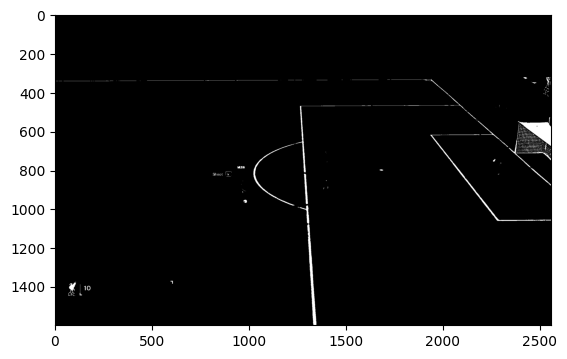

In [23]:

# frames = read_frames('./all/')
# frames = frames[0:100]
counter = 0
# for i,frame in enumerate(frames):
frame = cv2.imread('./cera.png')
mask,new_frame = mask_on_white(frame)
plt.imshow(mask, cmap='gray')
found = find_circles(mask,new_frame,1)
if found: 
    counter += 1
        
print("Total number of balls detected:", counter)
    

In [176]:
def test_mask_on_white(img):
    height, width = img.shape[:2]

    # Crop 20% of the height from the top
    crop_height = int(height * 0.22)
    # crop_width = int(width * 0.1)
    cropped_img = img[crop_height:]  # Crop from top and left
    # display the cropped image


# Your target BGR color
    bgr_color = np.uint8([[[181, 187, 173]]])  # BGR format
    hsv_color = cv2.cvtColor(bgr_color, cv2.COLOR_BGR2HSV)[0][0]
    # print("HSV color:", hsv_color)  # Just to check

    # Define a tolerance range
    h, s, v = hsv_color
    lower_bound = np.array([0,0, 200])  # Lower bound for hue, saturation, and value
    upper_bound = np.array([179, 50, 255])  # Upper bound for hue, saturation, and value

    # Convert input image to HSV
    hsv = cv2.cvtColor(cropped_img, cv2.COLOR_BGR2HSV)

    # Create the mask
    mask = cv2.inRange(hsv, lower_bound, upper_bound)

    kernel = np.ones((3, 3), np.uint8)  # Adjust size (e.g., 3x3 or 7x7) based on stripe width
    closed_image = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=2)
    # closed_image = mask

    plt.imshow(closed_image, cmap='gray')
    return closed_image,cropped_img






In [171]:
def test_find_circles(mask,frame):
    y_min = 0  # Top of the image (farthest from camera)
    y_max = frame.shape[0]  # Bottom of the image (closest to camera)

    # Area ranges at y_min and y_max (adjust these based on your observations)
    area_min_at_y_min = 40  # Smallest area when the ball is farthest
    area_max_at_y_min = 150
    area_min_at_y_max = 160  # Largest area when the ball is closest
    area_max_at_y_max = 600
    test_frame = frame.copy()
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    for cnt in contours:
        coor_x, coor_y, w, h = cv2.boundingRect(cnt)
        area = cv2.contourArea(cnt)

        # Linearly interpolate the area bounds based on y
        # Fraction of y between y_min and y_max
        y_fraction = (coor_y - y_min) / (y_max - y_min)
        
        # Interpolate area bounds
        area_min = area_min_at_y_min + y_fraction * (area_min_at_y_max - area_min_at_y_min)
        area_max = area_max_at_y_min + y_fraction * (area_max_at_y_max - area_max_at_y_min)

        # Adjust the condition dynamically
        # if 700 < coor_x < 800 :
        print("\nArea:", area , "Area_min:", area_min, "Area_max:", area_max )
        print("coor_x:", coor_x , "coor_y:", coor_y )
        if area_min < area < area_max:
            (x, y), radius = cv2.minEnclosingCircle(cnt)
            circularity = 4 * np.pi * area / (cv2.arcLength(cnt, True) ** 2)
            
            if circularity > 0.45:
            # print("Circularity:", circularity)
            #make the col
                cv2.circle(test_frame, (int(x), int(y)), int(radius), (255, 0, 0), 2)
                # area and circularity
                label = f"A:{area:.2f},C:{circularity:.2f},X:{coor_x:.2f},Y:{coor_y:.2f},MIN:{area_min:.2f},MAX:{area_max:.2f}"
                font = cv2.FONT_HERSHEY_SIMPLEX
                font_scale = 1
                thickness = 2
                text_size, _ = cv2.getTextSize(label, font, font_scale, thickness)
                text_x = int(x) + int(radius) + 5  # Position text to the right of the circle
                text_y = int(y) + int(text_size[1] // 2)  # Center text vertically with circle
                cv2.putText(test_frame, label, (text_x, text_y), font, font_scale, (0, 0, 0), thickness)
    
    plt.imshow(test_frame)


test

Area: 0.0 Area_min: 143.46153846153845 Area_max: 537.9807692307693
coor_x: 80 coor_y: 1076

Area: 0.0 Area_min: 143.26923076923077 Area_max: 537.2596153846155
coor_x: 96 coor_y: 1074

Area: 0.0 Area_min: 143.26923076923077 Area_max: 537.2596153846155
coor_x: 74 coor_y: 1074

Area: 0.0 Area_min: 143.07692307692307 Area_max: 536.5384615384614
coor_x: 73 coor_y: 1072

Area: 0.0 Area_min: 141.73076923076923 Area_max: 531.4903846153845
coor_x: 90 coor_y: 1058

Area: 184.5 Area_min: 140.28846153846155 Area_max: 526.0817307692307
coor_x: 161 coor_y: 1043

Area: 58.5 Area_min: 139.61538461538464 Area_max: 523.5576923076924
coor_x: 125 coor_y: 1036

Area: 66.5 Area_min: 137.78846153846155 Area_max: 516.7067307692307
coor_x: 593 coor_y: 1017

Area: 65.5 Area_min: 100.0 Area_max: 375.0
coor_x: 1016 coor_y: 624

Area: 4154.0 Area_min: 93.36538461538461 Area_max: 350.12019230769226
coor_x: 2121 coor_y: 555

Area: 0.0 Area_min: 93.07692307692307 Area_max: 349.03846153846155
coor_x: 2118 coor_y

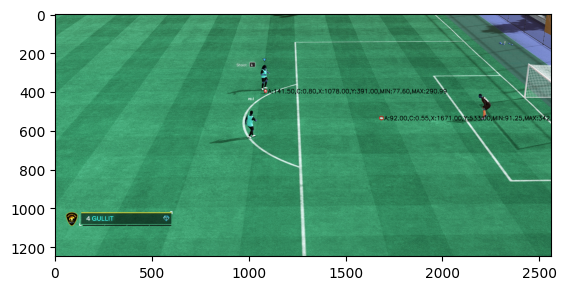

In [178]:
frames = read_frames('all')
frame = frames[3]
print("test")
mask,new_frame = test_mask_on_white(frame)
test_find_circles(mask,new_frame)


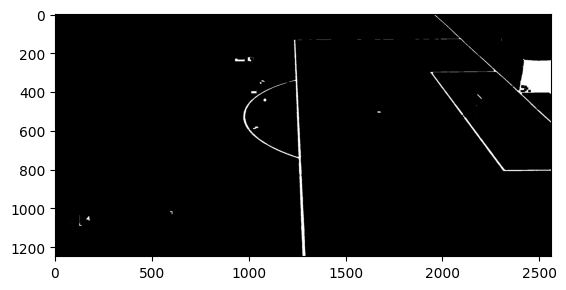

In [69]:
kernel = np.ones((5, 5), np.uint8)  # Adjust size (e.g., 3x3 or 7x7) based on stripe width
closed_image = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=2)
plt.imshow(closed_image, cmap='gray')

In [16]:
import os
import cv2

# Set the path to your image directory
image_dir = "is_ball"

# Make sure the path exists
if not os.path.isdir(image_dir):
    raise Exception(f"Directory '{image_dir}' not found!")

# List all files in the directory
files = os.listdir(image_dir)

# Loop through the files and rename image files
for i, filename in enumerate(sorted(files)):
    if filename.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tiff', '.gif')):
        old_path = os.path.join(image_dir, filename)


        # New filename format
        new_filename = f"frame_{i:03d}.jpg"  # zero-padded, e.g., debug_img_001.jpg
        new_path = os.path.join(image_dir, new_filename)

        # Rename file
        os.rename(old_path, new_path)
